In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import random
random.seed(0)

# Векторные представления (эмбеддинги) вершин графов на основе DeepWalk

DeepWalk — одно из первых крупных успешных применений методов машинного обучения (ML) к графовым данным. Задача DeepWalk — создавать представления, которые затем передаются другим моделям для решения, например, задачи классификации узлов.

Основные компоненты DeepWalk: Word2Vec и случайные блуждания.



## Word2Vec

Word2Vec  - методика преобразования слов в векторы - [была предложена в 2013 году Tomas Mikolov и соавторами](https://arxiv.org/abs/1301.3781). Эти векторные представления затем можно использовать для решения последующих задач, таких как классификация тональности текста. Это также один из редких примеров запатентованной и при этом широко популярной архитектуры машинного обучения.

**Continuous Bag-of-Words (CBOW):** Эта модель обучается предсказывать слово по его окружающему контексту (словам, которые находятся до и после целевого слова). Порядок слов в контексте не имеет значения, так как их векторные представления суммируются внутри модели. Авторы метода утверждают, что лучшие результаты достигаются при использовании четырех слов до и четырех слов после предсказываемого.

**Continuous Skip-gram:** В этой модели на вход подается одно слово, и она пытается предсказать окружающие его слова. Увеличение диапазона контекстных слов приводит к созданию более качественных векторных представлений, но также увеличивает время обучения.

![image.png](attachment:247705aa-a1e9-45a1-90e7-957afaf831b8.png)

**Skip-gram** - пара слов (target word, context word), где
- target word -  входное слово,
- context word - целевое слово (нужно предсказать).

Число skip-gram для одного исходного слова зависит от размера контекста (context size).

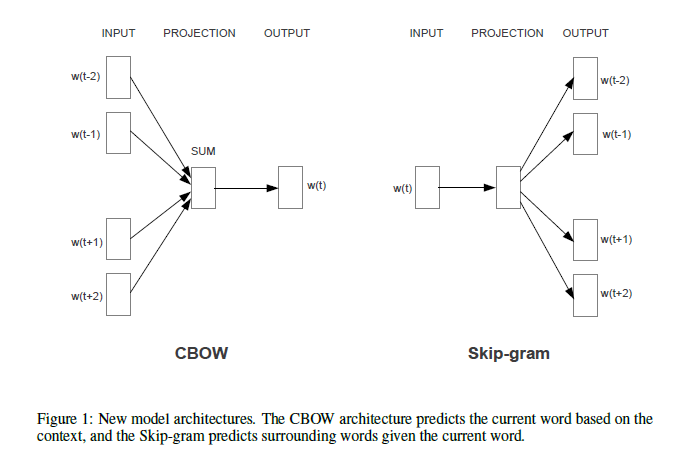

In [ ]:
CONTEXT_SIZE = 2

text = """The second architecture is similar to CBOW, but instead of predicting the current word based on the
context, it tries to maximize classification of a word based on another word in the same sentence.
More precisely, we use each current word as an input to a log-linear classifier with continuous
projection layer, and predict words within a certain range before and after the current word. We
found that increasing the range improves quality of the resulting word vectors, but it also increases
the computational complexity. Since the more distant words are usually less related to the current
word than those close to it, we give less weight to the distant words by sampling less from those
words in our training examples.
""".split()

In [ ]:
# Создадим skip-gram
skipgrams = []
for i in range(CONTEXT_SIZE, len(text) - CONTEXT_SIZE):
    array = [text[j] for j in np.arange(i - CONTEXT_SIZE, i + CONTEXT_SIZE + 1) if j != i]
    skipgrams.append((text[i], array))

print(skipgrams[0:2])

[('architecture', ['The', 'second', 'is', 'similar']), ('is', ['second', 'architecture', 'similar', 'to'])]


### The skip-gram model

Задача **Word2Vec** — создание векторных представлений слов (эмбеддингов). Чтобы выучить эти представления, задача обучения skip-gram модели состоит в том, чтобы предсказать правильные слова контекста по заданному целевому слову.

Пусть есть последовательносить из $N$ слов $w_{1},w_{2},\ldots,w_{N}$. $p(w_{2}|w_{1})$ - вероятность встретить слово $w_{2}$ при условии слова $w_{1}$. Задача — максимизировать сумму всех вероятностей встретить целевое  слово (context word)  при условии входного слова (target word) во всем тексте:

$$ \frac{1}{N}\sum_{n=1}^{N}\sum_{-C\leq j\leq C, \; j \neq 0}\log p(w_{n+j}|w_{n}) $$

где $С$ — размер контекстного окна.



Базовая skip-gram модель использует функцию softmax для вычисления вероятности вектора слова контекста $h_{c}$ при заданном векторе целевого слова $h_{t}$:

$$ p(w_{c}|w_{t})=\cfrac{\exp{(h_{c}\ h_{t}^{T})}}{\sum_{i=1}^{|V|}\exp{(h_{i}\ h_{t }^{T})}}$$

где $V$ — список уникальных слов (словарь), которые модель пытается предсказать.

Модель Skip-gram состоит всего из двух слоев:

*   **Projection Layer** с матрицей весов $W_{embed}$, который принимает на вход слово в виде one-hot вектора и возвращает соответствующее $N$-мерное векторное представление слова (эмбеддинг). Он действует как простая таблица поиска, которая хранит эмбеддинги заданной размерности.

*   **Fully Connected Layer** с матрицей весов $W_{output}$, который принимает на вход векторное представление слова и выдает логиты (логарифмы шансов) размерности $|V|$. К этим предсказаниям применяется функция softmax для преобразования логитов в вероятности.

 $x$ - one-hot вектор слова на входе. Вычисляем векторное представление слова (эмбеддинг) с помощью:

$$ h = W_{embed} \cdot x $$

Перепишем предыдущую формулу вероятности следующим образом:

$$ p(w_c | w_t) = \frac{\exp{(W_{output} \cdot h)}}{\sum_{i=1}^{|V|} \exp{(W_{output(i)}} \cdot h)} $$

Модель skip-gram возвращает вектор размерности $|V|$, который представляет собой условную вероятность для каждого слова в словаре:

$$ word2vec(w_t) =
\begin{bmatrix}
p(w_1 | w_t) \\
p(w_2 | w_t) \\
\vdots \\
p(w_{|V|} | w_t)
\end{bmatrix} $$

Во время обучения эти вероятности сравниваются с правильными one-hot векторами входных слов (target word). Разница между этими значениями (рассчитанная с помощью функции потерь, такой как перекрестная энтропия) обратно распространяется по сети для обновления весов и улучшения прогнозов.

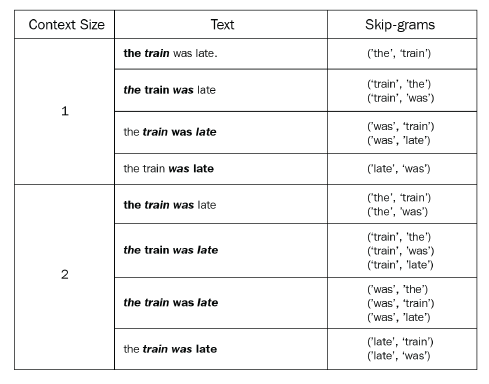

In [ ]:
!pip install -qU gensim
from gensim.models.word2vec import Word2Vec

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 24.3 MB/s eta 0:00:00


In [ ]:
model = Word2Vec([text],
                sg=1, # Skip-gram
                vector_size = 10,
                min_count = 0,
                window = 2,
                workers = 2,
                seed = 0)

In [ ]:
print(f'Shape of W_embed: {model.wv.vectors.shape}')

Shape of W_embed: (80, 10)


In [ ]:
model.train([text], total_examples=model.corpus_count, epochs=10)

(437, 1210)

In [ ]:
print('Word embedding =')
print(model.wv[0])

Word embedding =
[ 0.06741834  0.03318609  0.00406501 -0.04953263 -0.03636677 -0.08151371
 -0.08866009 -0.09487576 -0.06274761  0.06857495]


# DeepWalk and random walks

[DeepWalk: Online Learning of Social Representations](https://arxiv.org/abs/1403.6652)

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import random
random.seed(0)

In [ ]:
# Карате-клуб!

G = nx.karate_club_graph()

In [ ]:
# Создаем метки "Mr.Hi->0", "Officer->1"

labels = []
for node in G.nodes:
    label = G.nodes[node]["club"]
    labels.append(1 if label == 'Officer' else 0)

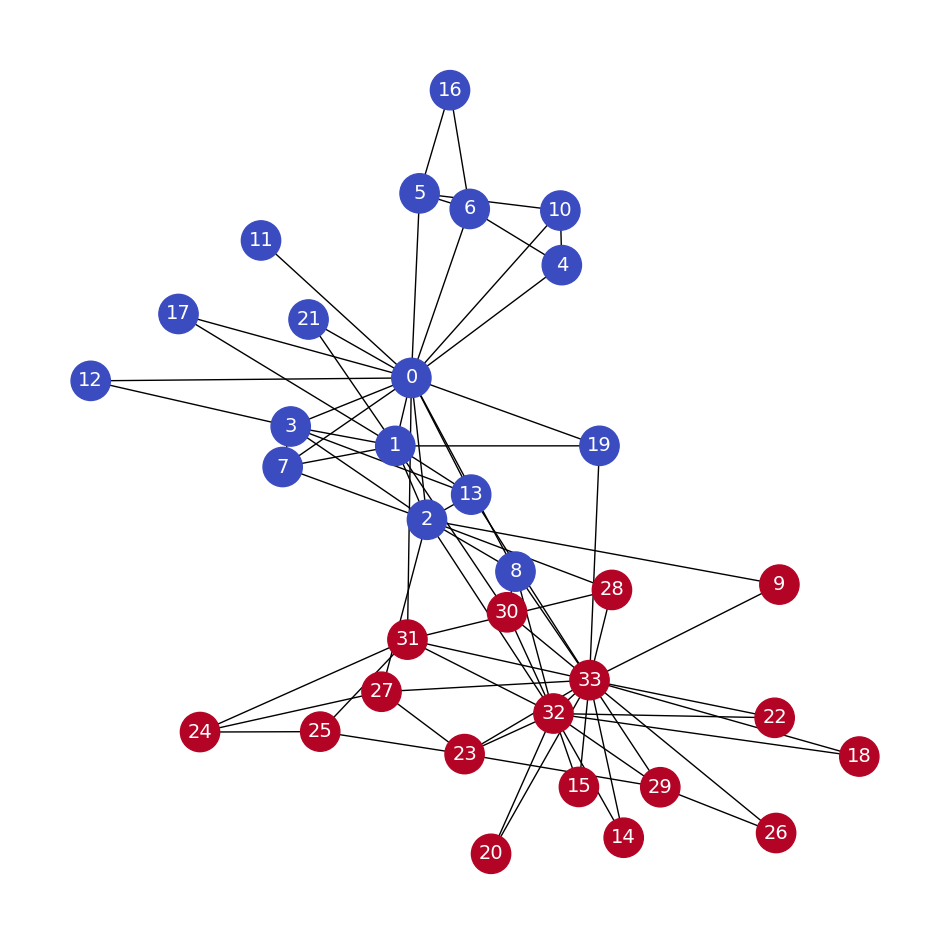

In [ ]:
# Нарисуем граф
plt.figure(figsize=(12,12))
plt.axis('off')
nx.draw_networkx(G,
                 pos=nx.spring_layout(G, seed=0),
                 node_color=labels,
                 node_size=800,
                 cmap='coolwarm',
                 font_size=14,
                 font_color='white'
                 )

## Случайные блуждания

In [ ]:
# Случайные блуждания

def random_walk(start, length):
    walk = [str(start)] # начальная вершина

    for i in range(length):
        neighbors = [node for node in G.neighbors(start)]
        next_node = np.random.choice(neighbors, 1)[0]
        walk.append(str(next_node))
        start = next_node

    return walk

In [ ]:
# Случайные блуждания из узла 0 длиной 10
print(random_walk(0, 10))

['0', '6', '4', '10', '4', '10', '5', '6', '5', '6', '16']


In [ ]:
# Для каждого узла создадим 80 "блужданий" длины 10
walks = []
for node in G.nodes:
    for _ in range(80):
        walks.append(random_walk(node, 10))

# Print the first random walk
print(walks[0])

['0', '17', '1', '13', '33', '29', '26', '29', '26', '29', '33']


Для создание эмбединнгов используем Word2Vec с H-Softmax.

In [ ]:
# Для создание эмбединнгов используем Word2Vec с H-Softmax.

model = Word2Vec(walks,
                hs = 1, # Hierarchical softmax
                sg = 1, # Skip-gram
                vector_size = 100,
                window = 10,
                workers = 1,
                seed  = 0)

In [ ]:
print(f'Shape of embedding matrix: {model.wv.vectors.shape}')

# Создаем словарь
model.build_vocab(walks)

# Обучаем модель
model.train(walks, total_examples=model.corpus_count, epochs=30, report_delay=1)

Shape of embedding matrix: (34, 100)


(187317, 897600)

In [ ]:
# Наиболее близкие узлы к 0
# близкие по косинусной мере
print('Узлы, наиболее ''похожие'' на узел 0:')
for similarity in model.wv.most_similar(positive=['0']):
    print(f'   {similarity}')

Узлы, наиболее похожие на узел 0:
   ('10', 0.7539915442466736)
   ('6', 0.7168199419975281)
   ('4', 0.6904749274253845)
   ('21', 0.6880766153335571)
   ('11', 0.6593830585479736)
   ('16', 0.6474539637565613)
   ('12', 0.638676643371582)
   ('5', 0.637185275554657)
   ('13', 0.6335217356681824)
   ('1', 0.6130298972129822)


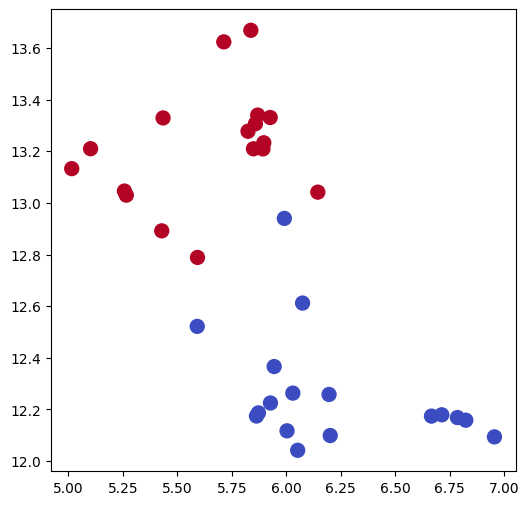

In [ ]:
# Визуализируем эмбединнги с помощью
# t-distributed stochastic neighbor embedding (t-SNE)
from sklearn.manifold import TSNE

nodes_wv = np.array([model.wv.get_vector(str(i)) for i in range(len(model.wv))])
labels = np.array(labels)

tsne = TSNE(n_components=2,
            learning_rate='auto',
            init='pca',
            random_state=0).fit_transform(nodes_wv)

# Plot TSNE
plt.figure(figsize=(6, 6))
plt.scatter(tsne[:, 0], tsne[:, 1], s=100, c=labels, cmap="coolwarm")
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Create masks to train and test the model
train_mask = [2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24]
test_mask = [0, 1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 26, 27, 28, 29, 30, 31, 32, 33]

# Обучаем классификатор
clf = RandomForestClassifier(random_state=0)
clf.fit(nodes_wv[train_mask], labels[train_mask])

# Считаем точность (accuracy)
y_pred = clf.predict(nodes_wv[test_mask])
acc = accuracy_score(y_pred, labels[test_mask])
print(f'Accuracy = {acc*100:.2f}%')

Accuracy = 95.45%


# Biased Random Walks (Node2Vec)

- Biased walk
- Можно исследовать локальную  или глобальную окрестности вершины
- Breadth-First Search, BFS - поиск в ширину
- Depth-First Search, DFS - поиск в глубину

- Локальная окрестность $N_{BFS} (u) = \{s_1, s_2, s_3\}$
- Глобальная  окрестность $N_{DFS} (u) = \{s_4, s_5, s_6\}$

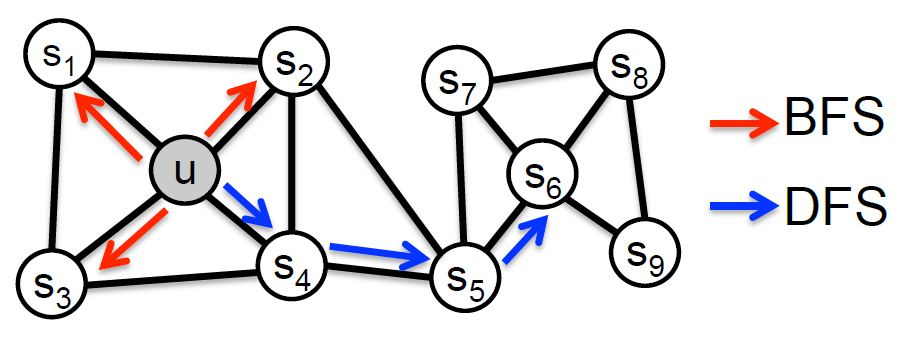

- Запоминаем предыдущий узел
- Два параметра $p$ и $q$
- $p$ - "вероятность"\, возврата   в предыдущий узел
- $q$ - "вероятность"\, продвижения дальше от узла (вглубь)

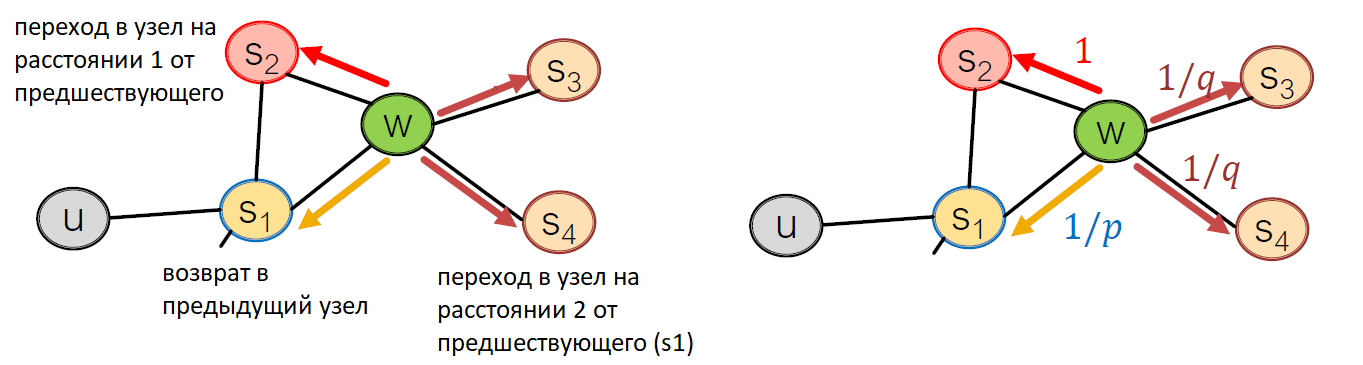

- $w$ - текущий узел, $s$ - предыдущий узел
- $x$ - возможный следующий узел в  блуждании
- Вероятность попасть в узел $x$ из узла $w$

$$ P(x|w) = \left\{
		\begin{array}{ll}
			\pi_{wx}/W, & \hbox{if } \;  (w,x) \in E \\
			0, & \hbox{иначе.}
		\end{array}
		\right.
$$

- $\pi_{wx}$ - вероятность перехода между узлами
- $W$ - константа нормирования
- Вероятность перехода в узел $x$, если пришли из узла $s$

$$ \pi_{wx} = \alpha_{pq} (s,x) \cdot w_{wx}, \;\;\;\;
		\alpha_{pq}(s, x) =
		\left\{
		\begin{array}{ll}
			1/p, & \hbox{if } \; d(s,x) = 0, \\
			1, & \hbox{if } \; d(s,x) = 1, \\
			1/q, & \hbox{if } \; d(s,x) = 2.
		\end{array}
\right.$$

- $p > \max (q, 1)$: вероятность вернуться за два шага в предыдущий узел мала
- $p < \min (q, 1)$: наиболее вероятен возврат к предыдущему узлу (блуждаем в ширину, BFS)
- $q > 1$: блуждание в ширину
- $q< 1$: блуждание в глубину (выше шанс уйти  от предыдущего узла вглубь графа)

Реализуем эту идею на случайном графе.

In [ ]:
import networkx as nx
import random
random.seed(0)
import numpy as np
np.random.seed(0)
import matplotlib.pyplot as plt

In [ ]:
G = nx.erdos_renyi_graph(10, 0.3, seed=1, directed=False)

/usr/local/lib/python3.12/dist-packages/networkx/drawing/nx_pylab.py:1438: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  node_collection = ax.scatter(


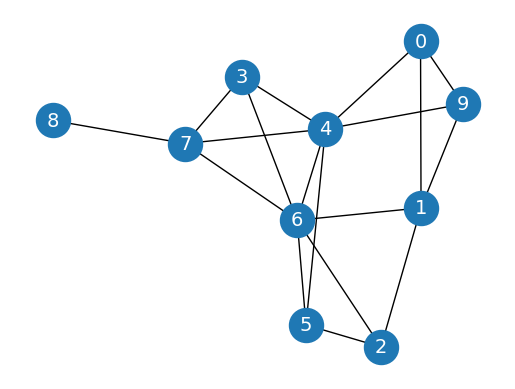

In [ ]:
plt.figure()
plt.axis('off')
nx.draw_networkx(G,
                 pos=nx.spring_layout(G, seed=0),
                 node_size=600,
                 cmap='coolwarm',
                 font_size=14,
                 font_color='white'
                 )

In [ ]:
def next_node(previous, current, p, q):
    alphas = []

    # Соседи узла
    neighbors = list(G.neighbors(current))

    # Вычисляем alpha
    for neighbor in neighbors:
        # Расстояние = 0: вероятность возврата в предыдущий узел
        if neighbor == previous:
            alpha = 1/p
        # Расстояние = 1: вероятность перейти в узел на расстоянии 1 (от предыдущего)
        elif G.has_edge(neighbor, previous):
            alpha = 1
        # Расстояние = 2: вероятность перейти в узел на расстоянии 2
        else:
            alpha = 1/q
        alphas.append(alpha)

    # Нормируем значения aplha
    probs = [alpha / sum(alphas) for alpha in alphas]

    # Выбираем узел для перехода
    next = np.random.choice(neighbors, size=1, p=probs)[0]
    return next

In [ ]:
def random_walk(start, length, p, q):
    walk = [start]

    for i in range(length):
        current = walk[-1]
        previous = walk[-2] if len(walk) > 1 else None
        next = next_node(previous, current, p, q)
        walk.append(next)

    return walk

In [ ]:
# Блуждание из узла 0 длины 8 (фактически получили DeepWalk)
random_walk(0, 8, p=1, q=1)

[0,
 np.int64(4),
 np.int64(7),
 np.int64(6),
 np.int64(4),
 np.int64(5),
 np.int64(4),
 np.int64(5),
 np.int64(6)]

In [ ]:
# Изменим параметры (возвращаемся к предыдущему узлу)
random_walk(0, 8, p=1, q=10)

[0,
 np.int64(9),
 np.int64(1),
 np.int64(9),
 np.int64(1),
 np.int64(9),
 np.int64(1),
 np.int64(0),
 np.int64(1)]

In [ ]:
# Еще раз поменяем параметры, исключая возможность возврата к предыдущему узлу
random_walk(0, 8, p=10, q=1)

[0,
 np.int64(1),
 np.int64(9),
 np.int64(4),
 np.int64(7),
 np.int64(8),
 np.int64(7),
 np.int64(4),
 np.int64(6)]

In [ ]:
# !pip install -q node2vec==0.4.6
# !pip install -qI gensim

In [ ]:
from gensim.models.word2vec import Word2Vec
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [ ]:
# Карате клуб
G = nx.karate_club_graph()

# Создаем метки (Mr. Hi = 0, Officer = 1)
labels = []
for node in G.nodes:
    label = G.nodes[node]['club']
    labels.append(1 if label == 'Officer' else 0)

# Случайные блуждания
walks = []
for node in G.nodes:
    for _ in range(80):
        walks.append(random_walk(node, 10, 3, 2))

# Создаем и обучаем модель Word2Vec for DeepWalk
node2vec = Word2Vec(walks,
                hs=1,   # Hierarchical softmax
                sg=1,   # Skip-gram
                vector_size=100,
                window=10,
                workers=2,
                min_count=1,
                seed=0)
node2vec.train(walks, total_examples=node2vec.corpus_count, epochs=30, report_delay=1)

# Размечаем узлы
train_mask = [2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24]
test_mask = [0, 1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 26, 27, 28, 29, 30, 31, 32, 33]
labels = np.array(labels)

# Тренируем классификатор
clf = RandomForestClassifier(random_state=0)
clf.fit(node2vec.wv[train_mask], labels[train_mask])

# Считаем точность модели (accuracy)
y_pred = clf.predict(node2vec.wv[test_mask])
acc = accuracy_score(y_pred, labels[test_mask])
print(f'Node2Vec accuracy = {acc*100:.2f}%')


Node2Vec accuracy = 95.45%


# Задание

1. Проверьте, как работает модель при изменении параметров $p, q$ от $1$ до $7$. Для каждой пары параметров вычислите среднее значение точности по результатам $100$ классификаций.

## Рекомендательная система на основе Node2Vec

In [ ]:
import pandas as pd

In [ ]:
# рейтинги пользователей
ratings = pd.read_csv('u.data', sep='\t',
names=['user_id', 'movie_id', 'rating', 'unix_timestamp'])
ratings

FileNotFoundError: [Errno 2] No such file or directory: 'u.data'

In [ ]:
# фильмы
movies = pd.read_csv('u.item', sep='|', usecols=range(2), names=['movie_id', 'title'], encoding='latin-1')
movies

In [ ]:
# оставляем только фильмы с рейтингом >=4
ratings = ratings[ratings.rating >= 4]
ratings

In [ ]:
from collections import defaultdict

pairs = defaultdict(int)

# Loop through the entire list of users
for group in ratings.groupby("user_id"):
    # List of IDs of movies rated by the current user
    user_movies = list(group[1]["movie_id"])

    # Count every time two movies are seen together
    for i in range(len(user_movies)):
        for j in range(i+1, len(user_movies)):
            pairs[(user_movies[i], user_movies[j])] += 1

In [ ]:
# Create a networkx graph
G = nx.Graph()

# Try to create an edge between movies that are liked together
for pair in pairs:
    movie1, movie2 = pair
    score = pairs[pair]

    # The edge is only created when the score is high enough
    if score >= 20:
        G.add_edge(movie1, movie2, weight=score)

print("Total number of graph nodes:", G.number_of_nodes())
print("Total number of graph edges:", G.number_of_edges())

In [ ]:
!pip install -q node2vec

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 71.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opencv-contrib-python 4.12.0.88 requires numpy<2.3.0,>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
jaxlib 0.7.2 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
opencv-python-headless 4.12.0.88 requires numpy<2.3.0,>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
jax 0.7.2 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
pytensor 2.35.1 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
thinc 8.3.6 requires numpy<3.0.0,>=2.0.0, but you have numpy 1.26.4 which is incompatible.
opencv-python 4.12.0.88 requires numpy<2.3.0,>=2; python_vers

In [ ]:
from node2vec import Node2Vec

In [ ]:
node2vec = Node2Vec(G, dimensions=64, walk_length=20, num_walks=200, p=2, q=1, workers=1)

model = node2vec.fit(window=10, min_count=1, batch_words=4)

In [ ]:
def recommend(movie):
    movie_id = str(movies[movies.title == movie].movie_id.values[0])
    for id in model.wv.most_similar(movie_id)[:5]:
        title = movies[movies.movie_id == int(id[0])].title.values[0]
        print(f'{title}: {id[1]:.2f}')

recommend('Home Alone (1990)')

In [ ]:
recommend('Pretty Woman (1990)')

#ДЗ


# Задание

1. Проверьте, как работает модель при изменении параметров $p, q$ от $1$ до $7$. Для каждой пары параметров вычислите среднее значение точности по результатам $100$ классификаций.

In [ ]:
!pip install -qU gensim
from gensim.models.word2vec import Word2Vec

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 55.2 MB/s eta 0:00:00


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

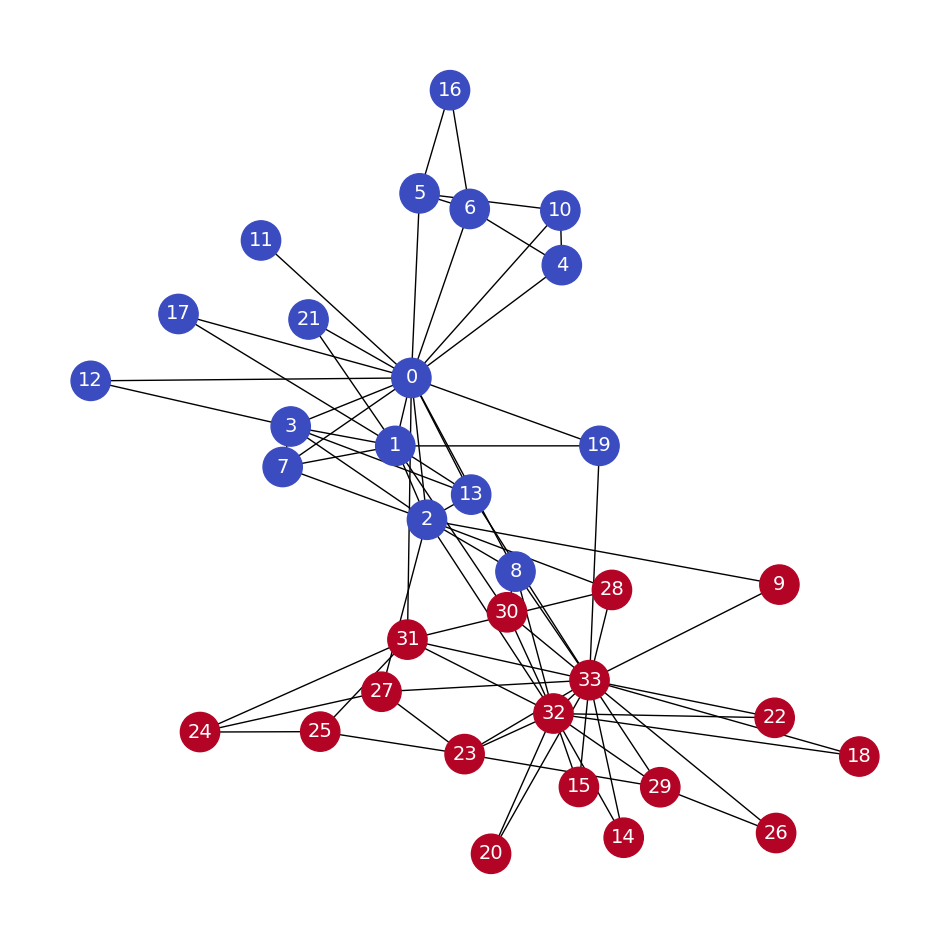

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import random
random.seed(0)
np.random.seed(0)

G = nx.karate_club_graph()

labels = []
for node in G.nodes:
    label = G.nodes[node]["club"]
    labels.append(1 if label == 'Officer' else 0)


# Нарисуем граф
plt.figure(figsize=(12,12))
plt.axis('off')
nx.draw_networkx(G,
                 pos=nx.spring_layout(G, seed=0),
                 node_color=labels,
                 node_size=800,
                 cmap='coolwarm',
                 font_size=14,
                 font_color='white'
                 )


In [ ]:
def next_node(previous, current, p, q):
    alphas = []

    neighbors = list(G.neighbors(current))

    # Вычисляем alpha
    for neighbor in neighbors:
        if neighbor == previous:
            alpha = 1/p
        elif G.has_edge(neighbor, previous):
            alpha = 1
        else:
            alpha = 1/q
        alphas.append(alpha)
    probs = [alpha / sum(alphas) for alpha in alphas]
    next = np.random.choice(neighbors, size=1, p=probs)[0]
    return next

In [ ]:
def random_walk(start, length, p, q):
    walk = [start]

    for i in range(length):
        current = walk[-1]
        previous = walk[-2] if len(walk) > 1 else None
        next = next_node(previous, current, p, q)
        walk.append(next)

    return walk

In [ ]:
# Блуждание из узла 0 длины 8 (фактически получили DeepWalk)
random_walk(0, 8, p=1, q=1)

[0,
 np.int64(10),
 np.int64(5),
 np.int64(10),
 np.int64(4),
 np.int64(6),
 np.int64(5),
 np.int64(6),
 np.int64(16)]

In [ ]:
G = nx.karate_club_graph()
labels = []
for node in G.nodes:
    label = G.nodes[node]['club']
    labels.append(1 if label == 'Officer' else 0)
walks = []
for node in G.nodes:
    for _ in range(80):
        walks.append(random_walk(node, 10, 3, 2))

node2vec = Word2Vec(walks,
                hs=1,   # Hierarchical softmax
                sg=1,   # Skip-gram
                vector_size=100,
                window=10,
                workers=2,
                min_count=1,
                seed=0)
node2vec.train(walks, total_examples=node2vec.corpus_count, epochs=30, report_delay=1)

# Размечаем узлы
train_mask = [2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24]
test_mask = [0, 1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 26, 27, 28, 29, 30, 31, 32, 33]
labels = np.array(labels)

# Тренируем классификатор
clf = RandomForestClassifier(random_state=0)
clf.fit(node2vec.wv[train_mask], labels[train_mask])

# Считаем точность модели (accuracy)
y_pred = clf.predict(node2vec.wv[test_mask])
acc = accuracy_score(y_pred, labels[test_mask])
print(f'Node2Vec accuracy = {acc*100:.2f}%')


Node2Vec accuracy = 100.00%


In [ ]:
def function(p_list, q_list, walk_list):
    labels = []
    for node in G.nodes:
        label = G.nodes[node]['club']
        labels.append(1 if label == 'Officer' else 0)

    results = []

    for p in p_list:
      for q in q_list:

        for w in walk_list:
          walks = []
          for node in G.nodes:
            for _ in range(80):
              walks.append(random_walk(node, p, q, w))

          node2vec = Word2Vec(walks,
                              hs=1,   # Hierarchical softmax
                              sg=1,   # Skip-gram
                              vector_size=100,
                              window=10,
                              workers=2,
                              min_count=1,
                              negative = 0,
                              seed=0)
          node2vec.train(walks, total_examples=node2vec.corpus_count, epochs=30, report_delay=1)
          # Разметка узлов
          train_mask = [2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24]
          test_mask = [0, 1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 26, 27, 28, 29, 30, 31, 32, 33]
          labels = np.array(labels)

          clf = RandomForestClassifier(random_state=0)
          clf.fit(node2vec.wv[train_mask], labels[train_mask])

          y_pred = clf.predict(node2vec.wv[test_mask])
          acc = accuracy_score(y_pred, labels[test_mask])
          results.append({
              'p': p,
              'q': q,
              'w': w,
              'accuracy': acc
          })
          #print(f'Node2Vec accuracy = {acc*100:.2f}%')
          print(f'For p={p}, q={q}, w={w}, accuracy={acc*100:.2f}%')

    return results


In [ ]:
from os import waitid
def function(p_list, q_list, walk_list):
    labels = []
    for node in G.nodes:
        label = G.nodes[node]['club']
        labels.append(1 if label == 'Officer' else 0)

    results = []

    for p in p_list:
        for q in q_list:
            for w in walk_list:

                acc_list = []
                for i in range(100):
                    walks = []
                    for node in G.nodes:
                        for _ in range(80):
                            walks.append(random_walk(node, p, q, w))

                    node2vec = Word2Vec(walks,
                                        hs=1,
                                        sg=1,
                                        vector_size=100,
                                        window=10,
                                        workers=2,
                                        min_count=1,
                                        negative=0,
                                        seed=i)#+p+q+w)  # меняем seed для разных запусков
                    node2vec.train(walks, total_examples=node2vec.corpus_count, epochs=30, report_delay=1)

                    train_mask = [2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24]
                    test_mask = [0, 1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 26, 27, 28, 29, 30, 31, 32, 33]
                    labels = np.array(labels)

                    clf = RandomForestClassifier(random_state=0)
                    clf.fit(node2vec.wv[train_mask], labels[train_mask])

                    y_pred = clf.predict(node2vec.wv[test_mask])
                    acc = accuracy_score(y_pred, labels[test_mask])
                    acc_list.append(acc)

                mean_accuracy = np.mean(acc_list)
                results.append({
                    'p': p,
                    'q': q,
                    'w': w,
                    'mean_accuracy': mean_accuracy
                })
                print(f'For p={p}, q={q}, w={w}, mean accuracy over 100 runs = {mean_accuracy*100:.2f}%')
    return results

In [ ]:
G = nx.karate_club_graph()
p_list=[1,2,3,4,5,6,7]
q_list=[1,2,3,4,5,6,7]
walk_list=[5, 10]
# p_list=[1]
# q_list=[1]
# walk_list=[5]
results = function(p_list, q_list, walk_list)

For p=1, q=1, w=5, mean accuracy over 100 runs = 67.23%


For p=1, q=1, w=10, mean accuracy over 100 runs = 65.55%


For p=1, q=2, w=5, mean accuracy over 100 runs = 67.77%


For p=1, q=2, w=10, mean accuracy over 100 runs = 66.18%


For p=1, q=3, w=5, mean accuracy over 100 runs = 68.00%


For p=1, q=3, w=10, mean accuracy over 100 runs = 66.45%


... (88 outputs left out)

For p=7, q=6, w=5, mean accuracy over 100 runs = 95.05%


For p=7, q=6, w=10, mean accuracy over 100 runs = 94.05%


For p=7, q=7, w=5, mean accuracy over 100 runs = 94.91%


For p=7, q=7, w=10, mean accuracy over 100 runs = 94.41%


In [ ]:
def print_results(results):
    print("Results (p, q, w, accuracy):")
    for res in results:
        p = res['p']
        q = res['q']
        w = res['w']
        accuracy = res['mean_accuracy']
        print(f"p={p}, q={q}, w={w}, accuracy={accuracy*100:.2f}%")

In [ ]:
print_results(results)

Results (p, q, w, accuracy):
p=1, q=1, w=5, accuracy=67.23%
p=1, q=1, w=10, accuracy=65.55%
p=1, q=2, w=5, accuracy=67.77%
p=1, q=2, w=10, accuracy=66.18%
p=1, q=3, w=5, accuracy=68.00%
p=1, q=3, w=10, accuracy=66.45%
p=1, q=4, w=5, accuracy=68.09%
p=1, q=4, w=10, accuracy=69.00%
p=1, q=5, w=5, accuracy=68.73%
p=1, q=5, w=10, accuracy=65.95%
p=1, q=6, w=5, accuracy=67.41%
p=1, q=6, w=10, accuracy=67.23%
p=1, q=7, w=5, accuracy=66.73%
p=1, q=7, w=10, accuracy=67.27%
p=2, q=1, w=5, accuracy=92.18%
p=2, q=1, w=10, accuracy=90.18%
p=2, q=2, w=5, accuracy=93.59%
p=2, q=2, w=10, accuracy=93.23%
p=2, q=3, w=5, accuracy=93.45%
p=2, q=3, w=10, accuracy=93.86%
p=2, q=4, w=5, accuracy=94.09%
p=2, q=4, w=10, accuracy=93.09%
p=2, q=5, w=5, accuracy=93.55%
p=2, q=5, w=10, accuracy=93.14%
p=2, q=6, w=5, accuracy=93.55%
p=2, q=6, w=10, accuracy=93.09%
p=2, q=7, w=5, accuracy=92.68%
p=2, q=7, w=10, accuracy=92.41%
p=3, q=1, w=5, accuracy=92.27%
p=3, q=1, w=10, accuracy=92.64%
p=3, q=2, w=5, accuracy=91

In [ ]:
def print_best_result(results):
    max_accuracy = -1
    best_params = None
    for res in results:
        if res['accuracy'] > max_accuracy:
            max_accuracy = res['accuracy']
            best_params = {'p': res['p'], 'q': res['q'], 'w': res['w']}
    print("\nНаилшее значение accuracy:")
    print(f"Accuracy = {max_accuracy*100:.2f}% при p={best_params['p']}, q={best_params['q']}, w={best_params['w']}")

In [ ]:
def print_best_result(results):
    max_accuracy = -1
    best_params = None
    for res in results:
        if res['mean_accuracy'] > max_accuracy:
            max_accuracy = res['mean_accuracy']
            best_params = {'p': res['p'], 'q': res['q'], 'w': res['w']}
    print("\nНаилшее значение accuracy:")
    print(f"Accuracy = {max_accuracy*100:.2f}% при p={best_params['p']}, q={best_params['q']}, w={best_params['w']}")

In [ ]:
print_best_result(results)


Наилшее значение accuracy:
Accuracy = 95.05% при p=7, q=6, w=5


In [ ]:
G = nx.karate_club_graph()
p_list=[1,2,3,4,5,6,7]
q_list=[1,2,3,4,5,6,7]
walk_list=[15, 20]
# p_list=[1]
# q_list=[1]
# walk_list=[5]
results = function(p_list, q_list, walk_list)

For p=1, q=1, w=15, mean accuracy over 100 runs = 66.82%


For p=1, q=1, w=20, mean accuracy over 100 runs = 65.73%


For p=1, q=2, w=15, mean accuracy over 100 runs = 68.18%


For p=1, q=2, w=20, mean accuracy over 100 runs = 67.41%


For p=1, q=3, w=15, mean accuracy over 100 runs = 68.05%


For p=1, q=3, w=20, mean accuracy over 100 runs = 67.86%


... (88 outputs left out)

For p=7, q=6, w=15, mean accuracy over 100 runs = 92.91%


For p=7, q=6, w=20, mean accuracy over 100 runs = 92.50%


For p=7, q=7, w=15, mean accuracy over 100 runs = 93.23%


For p=7, q=7, w=20, mean accuracy over 100 runs = 93.00%


In [ ]:
def print_best_result(results):
    max_accuracy = -1
    best_params = None
    for res in results:
        if res['mean_accuracy'] > max_accuracy:
            max_accuracy = res['mean_accuracy']
            best_params = {'p': res['p'], 'q': res['q'], 'w': res['w']}
    print("\nНаилшее значение accuracy:")
    print(f"Accuracy = {max_accuracy*100:.2f}% при p={best_params['p']}, q={best_params['q']}, w={best_params['w']}")

In [ ]:
p2 = print_best_result(results)


Наилшее значение accuracy:
Accuracy = 94.36% при p=2, q=6, w=20


In [ ]:
re2=print_results(results)

Results (p, q, w, accuracy):
p=1, q=1, w=15, accuracy=66.82%
p=1, q=1, w=20, accuracy=65.73%
p=1, q=2, w=15, accuracy=68.18%
p=1, q=2, w=20, accuracy=67.41%
p=1, q=3, w=15, accuracy=68.05%
p=1, q=3, w=20, accuracy=67.86%
p=1, q=4, w=15, accuracy=67.23%
p=1, q=4, w=20, accuracy=68.59%
p=1, q=5, w=15, accuracy=67.91%
p=1, q=5, w=20, accuracy=67.59%
p=1, q=6, w=15, accuracy=66.68%
p=1, q=6, w=20, accuracy=65.95%
p=1, q=7, w=15, accuracy=68.32%
p=1, q=7, w=20, accuracy=65.86%
p=2, q=1, w=15, accuracy=88.41%
p=2, q=1, w=20, accuracy=88.00%
p=2, q=2, w=15, accuracy=92.05%
p=2, q=2, w=20, accuracy=91.36%
p=2, q=3, w=15, accuracy=92.77%
p=2, q=3, w=20, accuracy=92.36%
p=2, q=4, w=15, accuracy=94.09%
p=2, q=4, w=20, accuracy=93.32%
p=2, q=5, w=15, accuracy=93.82%
p=2, q=5, w=20, accuracy=93.36%
p=2, q=6, w=15, accuracy=93.14%
p=2, q=6, w=20, accuracy=94.36%
p=2, q=7, w=15, accuracy=94.00%
p=2, q=7, w=20, accuracy=93.91%
p=3, q=1, w=15, accuracy=91.14%
p=3, q=1, w=20, accuracy=91.18%
p=3, q=2, w

In [ ]:
G = nx.karate_club_graph()
p_list=[1,2,3,4,5,6,7]
q_list=[1,2,3,4,5,6,7]
walk_list=[2,3,4,6,7,8,9]
# p_list=[1]
# q_list=[1]
# walk_list=[5]
results3 = function(p_list, q_list, walk_list)

For p=1, q=1, w=2, mean accuracy over 100 runs = 68.64%


For p=1, q=1, w=3, mean accuracy over 100 runs = 69.32%


For p=1, q=1, w=4, mean accuracy over 100 runs = 66.05%


For p=1, q=1, w=6, mean accuracy over 100 runs = 68.50%


For p=1, q=1, w=7, mean accuracy over 100 runs = 68.73%


For p=1, q=1, w=8, mean accuracy over 100 runs = 67.86%


... (333 outputs left out)

For p=7, q=7, w=6, mean accuracy over 100 runs = 94.82%


For p=7, q=7, w=7, mean accuracy over 100 runs = 94.91%


For p=7, q=7, w=8, mean accuracy over 100 runs = 94.18%


For p=7, q=7, w=9, mean accuracy over 100 runs = 94.50%


In [ ]:
p3 = print_best_result(results3)


Наилшее значение accuracy:
Accuracy = 95.59% при p=7, q=7, w=3
